**Praktikum Week 9 Mata Kuliah Kecerdasan Buatan** <br>
Materi: Neural Network <br>
By: TAP

In [1]:
%pip install numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# 1. Import library dan Load Dataset Baru
import tensorflow as tf
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

# Memuat dataset
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

# 2. Normalisasi nilai piksel ke rentang [0, 1]
train_images = train_images / 255.0
test_images = test_images / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


### Sel 1: Persiapan dan Preprocessing Data
Fungsi Utama: Memasukkan alat-alat (library) yang dibutuhkan, mengunduh data, dan menyiapkan data agar siap dipelajari oleh mesin.
import tensorflow as tf dkk: Mengimpor library TensorFlow (untuk membuat neural network), Matplotlib (untuk menggambar grafik/visualisasi), dan Numpy (untuk operasi matematika).
mnist.load_data(): Mengunduh dataset MNIST (angka tulisan tangan 0-9). Data langsung dibagi menjadi dua bagian:
train (data latih) untuk mengajari model.
test (data uji) untuk mengetes kepintaran model nanti.
train_images / 255.0: Normalisasi. Gambar digital memiliki nilai warna piksel dari 0 (hitam) hingga 255 (putih). Neural network lebih mudah dan cepat belajar jika angkanya dikecilkan menjadi rentang 0.0 hingga 1.0.

In [4]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense

# 3. Membuat Model Neural Network
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)), # Mengubah gambar 28x28 menjadi vektor 1D (784)
    tf.keras.layers.Dense(128, activation='relu'), # Hidden layer
    tf.keras.layers.Dense(10, activation='softmax') # Output layer untuk 10 kategori (angka 0-9)
])

# Melihat ringkasan arsitektur model
model.summary()


C:\Users\ASUS TUF\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Sel 2: Membangun Arsitektur Model
Fungsi Utama: Membuat kerangka/otak dari Artificial Neural Network (ANN).
Sequential([ ... ]): Memberi tahu TensorFlow bahwa untuk membuat model yang lapisannya berurutan dari depan ke belakang.
Flatten(input_shape=(28, 28)): Ini adalah pintu masuk (Input Layer). Karena gambar berukuran 2D (28x28 piksel), layer ini "meratakan" gambar tersebut menjadi satu baris panjang berisi 784 angka (vektor 1D).
Dense(128, activation='relu'): Ini adalah lapisan tersembunyi (Hidden Layer). Memiliki 128 "neuron" (sel saraf buatan). relu digunakan agar model bisa mempelajari pola gambar yang rumit (tidak sekadar garis lurus).
Dense(10, activation='softmax'): Ini adalah pintu keluar (Output Layer). Harus berjumlah 10 karena kita ingin menebak 10 angka (0, 1, 2, ..., 9). softmax berfungsi mengubah hasil perhitungan menjadi persentase keyakinan (misal: 90% yakin ini angka 7).
model.summary(): Menampilkan tabel ringkasan bentuk dan jumlah parameter (bobot) dari model yang baru saja dibuat.

In [5]:
# 4. Kompilasi Model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# 5. Melatih Model
print("Memulai pelatihan model...")
history = model.fit(train_images, train_labels, epochs=10, validation_data=(test_images, test_labels))

Memulai pelatihan model...
Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9249 - loss: 0.2614 - val_accuracy: 0.9572 - val_loss: 0.1399
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9659 - loss: 0.1145 - val_accuracy: 0.9709 - val_loss: 0.0948
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9765 - loss: 0.0785 - val_accuracy: 0.9727 - val_loss: 0.0833
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9826 - loss: 0.0583 - val_accuracy: 0.9749 - val_loss: 0.0788
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9874 - loss: 0.0446 - val_accuracy: 0.9758 - val_loss: 0.0763
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9905 - loss: 0.0342 - val_accuracy: 0.9773 - val_loss: 0.0743
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9934 - loss: 0.0262 - val_accuracy: 0.9771 - val_loss: 0.0766
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accurac

### Sel 3: Kompilasi dan Pelatihan Model
Fungsi Utama: Menetapkan aturan belajar dan mulai menyuruh model untuk belajar dari data latih.
model.compile(...):
optimizer='adam': Cara model mengoreksi kesalahannya saat belajar (Adam adalah algoritma yang sangat cepat dan efisien).
loss='sparse_categorical_crossentropy': Cara model menghitung "seberapa salah" tebakannya.
metrics=['accuracy']: disini ingin melihat seberapa akurat tebakan model (dalam persentase) selama proses belajar.
model.fit(...): Proses belajar dimulai! Model akan melihat data train sebanyak 10 putaran penuh (epochs=10). Di setiap putaran, ia juga akan mengetes dirinya sendiri menggunakan data test (validation_data) untuk melihat apakah ia benar-benar pintar atau cuma menghafal.

In [6]:
# 6. Evaluasi Model
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)
print(f'\nAkurasi pengujian (Test accuracy): {test_acc}')

313/313 - 1s - 2ms/step - accuracy: 0.9786 - loss: 0.0777

Akurasi pengujian (Test accuracy): 0.978600025177002


### Sel 4: Evaluasi Model
Fungsi Utama: Memberikan ujian akhir kepada model menggunakan data yang belum pernah ia gunakan untuk belajar.
model.evaluate(...): Menguji model menggunakan test_images dan mencocokkannya dengan test_labels (kunci jawaban).

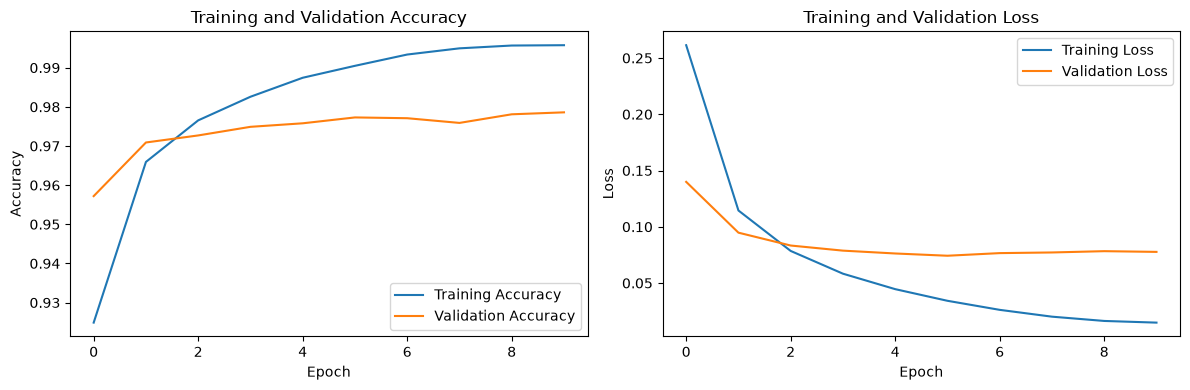

In [ ]:
# 7. Mendefinisikan fungsi untuk memvisualisasikan akurasi dan loss
def plot_history(history):
    # Plot akurasi
    plt.figure(figsize=(12, 4))

    # Plot Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')

    # Tampilkan plot
    plt.tight_layout()
    plt.show()

# Memanggil fungsi visualisasi
plot_history(history)

### Sel 5: Mendefinisikan Fungsi Visualisasi
Fungsi Utama: Membuat semacam "cetakan" (fungsi) untuk menggambar grafik.
def plot_history(history):: disini membuat fungsi sendiri. Di dalamnya, menggunakan matplotlib untuk menggambar dua buah grafik bersisian:
Grafik Kiri: Menunjukkan pergerakan Akurasi yang semakin naik dari epoch 1 ke epoch 10.
Grafik Kanan: Menunjukkan pergerakan Loss (Tingkat Error) yang semakin turun dari epoch 1 ke epoch 10.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


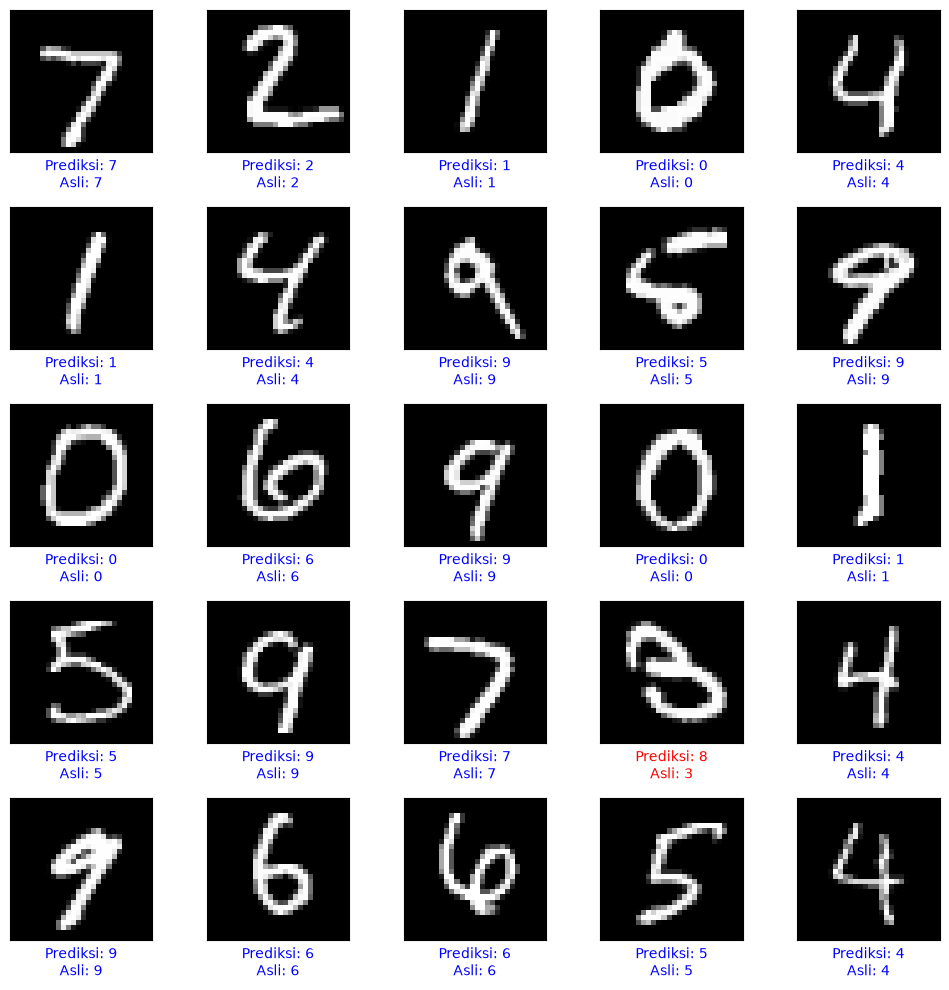

In [ ]:
# 8. Melakukan prediksi pada gambar pengujian
import numpy as np
predictions = model.predict(test_images)

# Contoh prediksi untuk 25 gambar pertama
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i], cmap='gray')
    predicted_label = np.argmax(predictions[i])
    actual_label = test_labels[i]
    # Teks biru jika benar, merah jika salah
    color = 'blue' if predicted_label == actual_label else 'red'
    plt.xlabel(f"Prediksi: {predicted_label}\nAsli: {actual_label}", color=color)
plt.tight_layout()
plt.show()

### Sel 6: Visualisasi Prediksi
Fungsi Utama: Menyuruh model menebak gambar dan menampilkannya ke layar beserta hasil tebakannya.
predictions = model.predict(test_images): Model memprediksi seluruh data pengujian. Hasilnya masih berupa deretan persentase probabilitas.
plt.figure... hingga for i in range(25):: Kita mengatur agar matplotlib menampilkan 25 gambar pertama dalam bentuk grid (5 baris x 5 kolom).
np.argmax(predictions[i]): Dari 10 probabilitas tebakan model untuk 1 gambar, fungsi ini mencari index (angka) dengan probabilitas paling tinggi. Itulah tebakan final si model (misal: "Saya paling yakin ini angka 7").
color = 'blue' if predicted == actual else 'red': Logika ini mengatur warna teks. Jika tebakan model SAMA dengan kunci jawaban aslinya, maka tulisan berwarna Biru. Jika tebakannya SALAH, tulisan berwarna Merah.

**Tugas** <br>
Implementasikan kode program di atas dengan dataset yang berbeda serta jelaskan apa yang Anda buat. Tugas dikumpulkan di hari Selasa, 3 Oktober 2026 jam 23.59 WIB di ecourse (baru).